# Expérimentations préliminaires — 0. Données et protocole

Jeu de données commun aux trois modèles (régression logistique, XGBoost, LSTM) et protocole
d'évaluation. Ce notebook ne contient aucun modèle : il produit les tableaux descriptifs du
rapport (données, plis, valeurs manquantes, redondance des variables).

**Protocole commun** (voir `src/nhl_forecast/features/equipes.py` et
`src/nhl_forecast/evaluation/preliminaire.py`) :

- saisons régulières **2009-10 à 2025-26**, statistiques d'**équipes** seulement, **toutes les
  colonnes** de `t_summary`, `t_percentages`, `t_summaryshooting`, `t_outshootoutshotby` et
  MoneyPuck (5 situations de jeu) ; seuls les identifiants, les colonnes vides ou constantes et
  les doublons exacts sont retirés, automatiquement ;
- validation **progressive** (*walk-forward*, fenêtre croissante) : chaque pli teste **une
  saison** et s'entraîne sur toutes les saisons antérieures ;
  - **développement** : plis 1 à 8, saisons testées 2016-17 à 2023-24 ;
  - **évaluation finale** : plis 9 et 10, saisons 2024-25 et 2025-26, réservées (à ne pas
    utiliser pour les choix de modélisation) ;
- hyperparamètres choisis sur les 20 % les plus récents des matchs d'entraînement du pli ;
- métriques : log loss, score de Brier, accuracy (seuil 0,5), résumées séparément pour chaque
  phase.

Écart avec le protocole proposé (initialisation 2005-06 à 2007-08, développement à partir de
2008-09) : MoneyPuck ne commence qu'en 2008-09, et `t_percentages` / `t_summaryshooting` en
2009-10. Les saisons 2005-06 à 2008-09 sont donc exclues de ce jeu de statistiques d'équipes ;
elles pourront servir à l'initialisation des modèles qui n'utilisent que les résultats (Elo).

Avec `SAUVER = True`, les tableaux sont enregistrés en CSV (séparateur « ; ») dans
`reports/map6009/tables/` (préfixe `exp_`) et les prédictions dans
`data/processed/experimentation/` (lues par `04_comparaison.ipynb`).

L'ancien protocole (2020-21 à 2025-26, une saison testée par pli ; rapport préliminaire 1) reste
disponible en définissant `NHL_EXP=base` avant les imports ; ses sorties sont suffixées `_base`
(`tables_base/`, `figures_base/`, `experimentation_base/`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from nhl_forecast.evaluation.preliminaire import (
    FIG_DIR,
    GRAINE,
    exporter_tableau,
    formater,
    plis_chronologiques,
    tableau_plis,
)
from nhl_forecast.features.equipes import (
    FENETRE,
    NOM_SAISON,
    SEP,
    bilan_colonnes,
    charger_equipes,
    colonnes_stats,
    construire_matchs,
    variables,
)
from nhl_forecast.visualization.style import ENCRE, appliquer_style

SAUVER = True
appliquer_style()

In [2]:
eq = charger_equipes()          # une équipe-match par ligne (valeurs du match)
matchs = construire_matchs(eq)  # un match par ligne, variables d'avant-match
STATS = colonnes_stats(eq)
X_cols = variables(matchs)
print(f"{len(eq)} équipes-matchs, {len(matchs)} matchs, {len(STATS)} statistiques, "
      f"{len(X_cols)} variables explicatives")

40764 équipes-matchs, 20382 matchs, 529 statistiques, 1060 variables explicatives


C:\Users\tom_9\Projets\nhl-probabilistic-forecasting\src\nhl_forecast\features\equipes.py:205: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  matchs = matchs.astype({"visiteur": "int64"}).reset_index()


## 1. Variables

Toutes les colonnes numériques des cinq sources sont utilisées (aucune sélection manuelle).
Pour MoneyPuck, chaque statistique est prise dans les cinq situations de jeu (`all`, `5on5`,
`5on4`, `4on5`, `other`). Retraits automatiques : colonnes vides ou constantes (ex.
`gamesPlayed`, toujours 1) et doublons exacts (ex. `pointPct`, présent dans plusieurs
rapports de la LNH).

Pour chaque statistique, deux variables **d'avant-match** :

- `_saison` : moyenne des matchs précédents de la saison ;
- `_10` : moyenne des 10 derniers matchs (forme récente / momentum, au moins 3 matchs).

S'y ajoutent les jours de repos et le nombre de matchs joués. Chaque variable de match est
l'écart **local − visiteur** (préfixe `d_`). Le décalage d'un match appliqué avant toute
moyenne garantit qu'aucune statistique du match à prédire n'est utilisée.

In [3]:
NOMS_SOURCES = {
    "summary": "LNH – t_summary", "percentages": "LNH – t_percentages",
    "summaryshooting": "LNH – t_summaryshooting", "outshootoutshotby": "LNH – t_outshootoutshotby",
    "mp_all": "MoneyPuck – all", "mp_5on5": "MoneyPuck – 5on5", "mp_5on4": "MoneyPuck – 5on4",
    "mp_4on5": "MoneyPuck – 4on5", "mp_other": "MoneyPuck – other",
}
tab_sources = bilan_colonnes()
tab_sources["Retirées"] = tab_sources["Colonnes numériques"] - tab_sources["Retenues"]
tab_sources["Source"] = pd.Categorical(tab_sources["Source"].map(NOMS_SOURCES),
                                       list(NOMS_SOURCES.values()), ordered=True)
tab_sources = tab_sources.sort_values("Source")
tab_sources["Source"] = tab_sources["Source"].astype(str)
tab_sources.loc[len(tab_sources)] = ["Contexte (repos, matchs joués)", 2, 2, 0]
tot = tab_sources.drop(columns="Source").sum()
tab_sources.loc[len(tab_sources)] = ["Total", *tot.astype(int)]
tab_sources = tab_sources[["Source", "Colonnes numériques", "Retirées", "Retenues"]]
tab_vars = pd.DataFrame([c.split(SEP) for c in STATS], columns=["Source", "Statistique"])
tab_vars["Source"] = tab_vars["Source"].map(NOMS_SOURCES)
if SAUVER:
    exporter_tableau(tab_sources, "exp_sources")
    exporter_tableau(tab_vars, "exp_variables")  # liste complète des statistiques retenues
formater(tab_sources)

Source,Colonnes numériques,Retirées,Retenues
LNH – t_summary,21,4,17
LNH – t_percentages,18,1,17
LNH – t_summaryshooting,16,1,15
LNH – t_outshootoutshotby,22,12,10
MoneyPuck – all,100,0,100
MoneyPuck – 5on5,100,0,100
MoneyPuck – 5on4,100,10,90
MoneyPuck – 4on5,100,10,90
MoneyPuck – other,100,10,90
"Contexte (repos, matchs joués)",2,0,2


## 2. Matchs par saison

In [4]:
tab_saisons = (
    matchs.groupby("saison")
    .agg(Matchs=("gameId", "size"), Victoires_locales=("victoire_locale", "mean"),
         Debut=("date", "min"), Fin=("date", "max"))
    .reset_index()
)
tab_saisons["saison"] = tab_saisons["saison"].map(NOM_SAISON)
tab_saisons[["Debut", "Fin"]] = tab_saisons[["Debut", "Fin"]].apply(lambda s: s.dt.strftime("%Y-%m-%d"))
tab_saisons = tab_saisons.rename(columns={"saison": "Saison", "Victoires_locales": "% victoires locales",
                                          "Debut": "Début"})
if SAUVER:
    exporter_tableau(tab_saisons, "exp_saisons")
formater(tab_saisons, 3)

Saison,Matchs,% victoires locales,Début,Fin
2009-10,1230,0.561,2009-10-01,2010-04-11
2010-11,1230,0.519,2010-10-07,2011-04-10
2011-12,1230,0.559,2011-10-06,2012-04-07
2012-13,720,0.568,2013-01-19,2013-04-28
2013-14,1230,0.537,2013-10-01,2014-04-13
2014-15,1230,0.541,2014-10-08,2015-04-11
2015-16,1230,0.529,2015-10-07,2016-04-10
2016-17,1230,0.559,2016-10-12,2017-04-09
2017-18,1271,0.563,2017-10-04,2018-04-08
2018-19,1271,0.537,2018-10-03,2019-04-06


Trois saisons sont raccourcies : 2012-13 (lock-out, 48 matchs par équipe), 2019-20
(interrompue par la pandémie, ≈ 70 matchs par équipe) et 2020-21 (56 matchs, joués à huis
clos en grande partie : l'avantage de la glace y est plus faible). Elles sont conservées ;
2019-20 et 2020-21 font partie des saisons testées (plis 4 et 5).

## 3. Plis chronologiques

Validation progressive (*walk-forward*), une saison testée par pli : plis 1 à 8 =
développement (2016-17 à 2023-24), plis 9 et 10 = évaluation finale (2024-25 et 2025-26). La date maximale d'entraînement est toujours
antérieure à la date minimale de test (vérifié par `assert` dans `plis_chronologiques`).

In [5]:
tab_plis = tableau_plis(matchs)
if SAUVER:
    exporter_tableau(tab_plis, "exp_plis")
formater(tab_plis)

Pli,Phase,Saisons d'entraînement,Saison testée,Matchs (entraînement),dont validation interne,Matchs (test)
1,Développement,2009-10 à 2015-16,2016-17,8100,1620,1230
2,Développement,2009-10 à 2016-17,2017-18,9330,1866,1271
3,Développement,2009-10 à 2017-18,2018-19,10601,2120,1271
4,Développement,2009-10 à 2018-19,2019-20,11872,2374,1082
5,Développement,2009-10 à 2019-20,2020-21,12954,2591,868
6,Développement,2009-10 à 2020-21,2021-22,13822,2764,1312
7,Développement,2009-10 à 2021-22,2022-23,15134,3027,1312
8,Développement,2009-10 à 2022-23,2023-24,16446,3289,1312
9,Évaluation finale,2009-10 à 2023-24,2024-25,17758,3552,1312
10,Évaluation finale,2009-10 à 2024-25,2025-26,19070,3814,1312


## 4. Valeurs manquantes

Deux origines :

- **début de saison** : aucune moyenne au premier match d'une équipe, aucune forme récente
  avant son 4e match, pas de jours de repos au premier match ;
- **statistiques non définies** pour certains matchs (ex. % en avantage numérique sans
  avantage numérique, % de tirs quand le score est serré si le match ne l'a jamais été).

Traitement retenu (ajusté sur l'entraînement du pli seulement) :

- régression logistique : imputation par la médiane, puis standardisation et ACP ;
- XGBoost : imputation par la médiane, puis standardisation et ACP (comme la régression
  logistique) ;
- LSTM : imputation par la médiane des équipes-matchs, standardisation et ACP ; séquences
  plus courtes que 20 rembourrées par des 0 et masquées.

In [6]:
groupes = {
    "Moyenne de la saison (_saison)": [c for c in X_cols if c.endswith("_saison")],
    f"Forme récente (_{FENETRE})": [c for c in X_cols if c.endswith(f"_{FENETRE}")],
    "Jours de repos": ["d_repos"],
}
lignes = []
for nom, cols in groupes.items():
    manq = matchs[cols].isna()
    lignes.append({"Groupe de variables": nom, "Variables": len(cols),
                   "% des valeurs manquantes": 100 * manq.to_numpy().mean(),
                   "% matchs avec ≥ 1 manquant": 100 * manq.any(axis=1).mean()})
manq_tout = matchs[X_cols].isna()
lignes.append({"Groupe de variables": "Toutes", "Variables": len(X_cols),
               "% des valeurs manquantes": 100 * manq_tout.to_numpy().mean(),
               "% matchs avec ≥ 1 manquant": 100 * manq_tout.any(axis=1).mean()})
tab_manq = pd.DataFrame(lignes)
if SAUVER:
    exporter_tableau(tab_manq, "exp_manquants", 2)
formater(tab_manq, 2)

Groupe de variables,Variables,% des valeurs manquantes,% matchs avec ≥ 1 manquant
Moyenne de la saison (_saison),529,1.55,3.44
Forme récente (_10),529,4.39,10.48
Jours de repos,1,1.54,1.54
Toutes,1060,2.97,10.48


In [7]:
# Où se trouvent les manquants : selon le nombre de matchs déjà joués par l'équipe locale
joues = eq.groupby(["saison", "teamId"]).cumcount()
eq_loc = eq.assign(joues=joues)[eq["domicile"] == 1][["gameId", "joues"]]
tranche = pd.cut(matchs.merge(eq_loc, on="gameId")["joues"], [-1, 0, 2, 9, 200],
                 labels=["1er match", "2e-3e", "4e-10e", "11e et +"])
part = manq_tout.mean(axis=1)
tab_manq_debut = (pd.DataFrame({"tranche": tranche.to_numpy(), "part": 100 * part.to_numpy()})
                  .groupby("tranche", observed=True)["part"].agg(["size", "mean"])
                  .rename(columns={"size": "Matchs", "mean": "% des valeurs manquantes"})
                  .rename_axis("Matchs joués (local)").reset_index())
formater(tab_manq_debut, 2)

Matchs joués (local),Matchs,% des valeurs manquantes
11e et +,17758,0.02
1er match,287,99.91
2e-3e,502,52.82
4e-10e,1835,2.67


## 5. Redondance des variables et ACP

Avec toutes les colonnes des cinq sources, beaucoup de variables mesurent presque la même
chose (Corsi de la LNH et de MoneyPuck, tirs pour/contre et écart de tirs, xG bruts et
ajustés, même statistique dans plusieurs situations…). L'ACP résume cette information
redondante en peu de composantes. Elle est ajustée ici sur l'entraînement du dernier pli
(2009-10 à 2023-24), après imputation et standardisation.

In [8]:
corr = np.abs(np.corrcoef(SimpleImputer(strategy="median").fit_transform(matchs[X_cols]),
                          rowvar=False))
iu = np.triu_indices_from(corr, k=1)
vals = np.nan_to_num(corr[iu])
tab_corr = pd.DataFrame({
    "Seuil |r|": [0.7, 0.8, 0.9, 0.99],
    "Paires de variables": [int((vals >= s).sum()) for s in (0.7, 0.8, 0.9, 0.99)],
})
tab_corr["% des paires"] = 100 * tab_corr["Paires de variables"] / len(vals)
if SAUVER:
    exporter_tableau(tab_corr, "exp_correlations", 2)
formater(tab_corr, 2)

Seuil |r|,Paires de variables,% des paires
0.70,7865,1.40
0.80,3823,0.68
0.90,1722,0.31
0.99,135,0.02


In [9]:
pli5 = plis_chronologiques(matchs)[-1]
acp = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), PCA(random_state=GRAINE))
acp.fit(matchs.iloc[pli5["entr"]][X_cols])
var_cum = np.cumsum(acp[-1].explained_variance_ratio_)
valeurs_propres = acp[-1].explained_variance_  # variables standardisées : λ moyen = 1
n_kaiser = int((valeurs_propres > 1).sum())
SEUILS = (0.8, 0.9, 0.95, 0.99)
n_seuils = [int(np.searchsorted(var_cum, s) + 1) for s in SEUILS]
tab_acp = pd.DataFrame({
    "Critère": [f"{s:.0%} de la variance" for s in SEUILS] + ["Kaiser (λ > 1)"],
    "Composantes": n_seuils + [n_kaiser],
    "Variance expliquée (%)": [100 * var_cum[n - 1] for n in n_seuils + [n_kaiser]],
})
tab_acp["sur"] = len(X_cols)
if SAUVER:
    exporter_tableau(tab_acp, "exp_acp", 1)
formater(tab_acp, 1)

Critère,Composantes,Variance expliquée (%),sur
80% de la variance,85,80.0,1060
90% de la variance,160,90.1,1060
95% de la variance,230,95.0,1060
99% de la variance,365,99.0,1060
Kaiser (λ > 1),159,90.0,1060


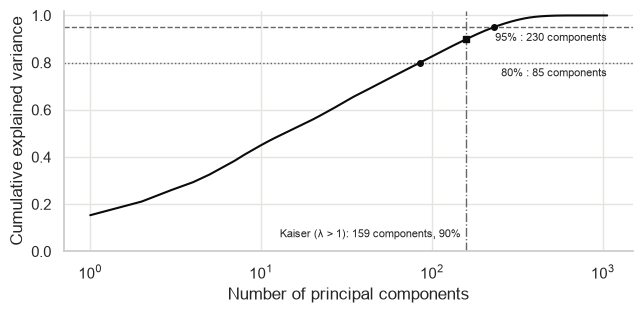

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
k = np.arange(1, len(var_cum) + 1)
ax.plot(k, var_cum, color=ENCRE, linestyle="-", marker="")
for s, style in ((0.8, ":"), (0.95, "--")):
    n = np.searchsorted(var_cum, s) + 1
    ax.axhline(s, color="0.4", linestyle=style, linewidth=1, marker="")
    ax.plot(n, var_cum[n - 1], color=ENCRE, marker="o", linestyle="")
    ax.annotate(f"{s:.0%} : {n} components", (len(k), s), xytext=(0, -4),
                textcoords="offset points", ha="right", va="top", fontsize=8)
ax.axvline(n_kaiser, color="0.4", linestyle="-.", linewidth=1, marker="")
ax.plot(n_kaiser, var_cum[n_kaiser - 1], color=ENCRE, marker="s", linestyle="")
ax.annotate(f"Kaiser (λ > 1): {n_kaiser} components, {var_cum[n_kaiser - 1]:.0%}",
            (n_kaiser, 0.05), xytext=(-4, 0), textcoords="offset points",
            ha="right", va="bottom", fontsize=8)
ax.set(xlabel="Number of principal components", ylabel="Cumulative explained variance",
       ylim=(0, 1.02), xscale="log")
fig.tight_layout()
if SAUVER:
    fig.savefig(FIG_DIR / "exp_variance_acp.png", dpi=300, bbox_inches="tight")
plt.show()

### Visualisation 3D interactive des 3 premières composantes

Même prétraitement que `01_regression_logistique` (imputation par la médiane → standardisation
→ ACP de Kaiser), ajusté sur les matchs d'entraînement du dernier pli. 1 000 matchs
d'entraînement tirés au hasard sont projetés sur les 3 premières composantes (part de la
variance totale entre parenthèses). Couleur **et** symbole selon le résultat (● victoire locale,
✕ défaite locale). La figure se fait pivoter à la souris ; le survol affiche le match.
Enregistrée en HTML (`exp_acp_3d.html`), ouvrable dans un navigateur.

In [ ]:
import plotly.graph_objects as go

from nhl_forecast.evaluation.preliminaire import ACPKaiser

# Même prétraitement que 01_regression_logistique (imputation médiane → standardisation →
# ACP de Kaiser), ajusté sur l'entraînement du dernier pli ; 1 000 matchs tirés au hasard.
N_POINTS = 1000
pli_3d = plis_chronologiques(matchs)[-1]
X_entr = matchs.iloc[pli_3d["entr"]][X_cols]
pre_3d = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                       ACPKaiser(random_state=GRAINE)).fit(X_entr)
Z = pre_3d.transform(X_entr)
var_tot = pre_3d[:-1].transform(X_entr).var(axis=0).sum()  # variance totale (standardisée)
part = Z[:, :3].var(axis=0) / var_tot
ech = np.random.default_rng(GRAINE).choice(len(Z), size=min(N_POINTS, len(Z)), replace=False)
Z3, y3 = Z[ech, :3], matchs.iloc[pli_3d["entr"]]["victoire_locale"].to_numpy()[ech]
infos = matchs.iloc[pli_3d["entr"]].iloc[ech]
texte = (infos["date"].dt.strftime("%Y-%m-%d") + " : " + infos["visiteur_nom"].astype(str) + " @ "
         + infos["local_nom"].astype(str)).to_numpy()

fig = go.Figure()
for val, nom, couleur, symbole in [(1, "Home win", "#2a78d6", "circle"),
                                   (0, "Home loss", "#eb6834", "x")]:
    m = y3 == val
    fig.add_trace(go.Scatter3d(
        x=Z3[m, 0], y=Z3[m, 1], z=Z3[m, 2], mode="markers", name=f"{nom} (n = {m.sum()})",
        marker=dict(size=3.5, color=couleur, symbol=symbole, opacity=0.8,
                    line=dict(width=0.5, color="black")),
        text=texte[m], hovertemplate="%{text}<br>PC1 %{x:.2f}<br>PC2 %{y:.2f}<br>PC3 %{z:.2f}"
                                      "<extra>" + nom + "</extra>",
    ))
fig.update_layout(
    scene=dict(xaxis_title=f"PC1 ({part[0]:.1%})", yaxis_title=f"PC2 ({part[1]:.1%})",
               zaxis_title=f"PC3 ({part[2]:.1%})"),
    title=f"First 3 principal components – {len(ech)} random training games "
          f"(fold {pli_3d['pli']}, {pre_3d[-1].n_components_} components kept)",
    legend=dict(itemsizing="constant"), width=850, height=700, margin=dict(l=0, r=0, b=0, t=50),
)
if SAUVER:
    fig.write_html(FIG_DIR / "exp_acp_3d.html", include_plotlyjs="cdn")  # ouvrable dans un navigateur
# Scatter3d exige WebGL, souvent indisponible dans la sortie des notebooks de VS Code :
# la figure s'ouvre dans le navigateur par défaut.
fig.show(renderer="browser")